In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive"

# All 8 dataset folders
dataset_dirs = [
    os.path.join(base_path, "Suitable"),
    os.path.join(base_path, "Not-Suitable"),

    os.path.join(base_path, "Sakshi_suitable"),
    os.path.join(base_path, "sakshi_not-suitable"),

    os.path.join(base_path, "rucha_suitable"),
    os.path.join(base_path, "rucha_not-suitable"),

    os.path.join(base_path, "mayuri_suitable"),
    os.path.join(base_path, "mayuri_not-suitable")
]

# Check all folders
for folder in dataset_dirs:
    print(
        os.path.basename(folder),
        "exists:",
        os.path.exists(folder)
    )

Suitable exists: True
Not-Suitable exists: True
Sakshi_suitable exists: True
sakshi_not-suitable exists: True
rucha_suitable exists: True
rucha_not-suitable exists: True
mayuri_suitable exists: True
mayuri_not-suitable exists: True


In [ ]:
print("\n" + "="*70)
print("ALL DATASET REGIONS")
print("="*70)

for folder in dataset_dirs:

    folder_name = os.path.basename(folder)

    print(f"\n📁 {folder_name}")

    if not os.path.exists(folder):
        print("   ❌ Folder not found")
        continue

    regions = sorted([
        r for r in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, r))
    ])

    print(f"   Number of regions: {len(regions)}")

    for region in regions:
        print(f"      - {region}")


ALL DATASET REGIONS

📁 Suitable
   Number of regions: 16
      - Almora_Test
      - Auli_Test
      - Dalhousie_Test
      - Dharamshala_Test
      - Kasauli_Test
      - Kausani_Test
      - Kodaikanal_Test
      - Lonavala_Test
      - Mahabaleshwar_Test
      - Manali_Test
      - Matheran_Test
      - Mount_Abu_Test
      - Mussoorie_Test
      - Nainital_Test
      - Ranikhet_Test
      - Shimla_Test

📁 Not-Suitable
   Number of regions: 10
      - Barmer_Test
      - Bikaner_dry_rocky_terrain_Test
      - Bundelkhand_Test
      - Chambal_ravines_Test
      - Deccan_Plateau_Test
      - Jaisalmer_Test
      - Jodhpur_rocky_Test
      - Quarry_region_near_Pune_Test
      - Rann_Kutch_Test
      - Stone_quarry_belt_near_Nashik_Test

📁 Sakshi_suitable
   Number of regions: 10
      - Bhandardara_Dam_Test
      - Dudhsagar_Falls_Test
      - Gobind_Sagar_Lake_Test
      - Naini_Lake_Test
      - Pong_Dam_Reservoir_Test
      - Rihand_Reservoir_Test
      - Sukhna_Lake_Test
      - T

In [ ]:
total_patches = 0

print("\n" + "="*70)
print("PATCH COUNT")
print("="*70)

for folder in dataset_dirs:

    folder_name = os.path.basename(folder)

    folder_count = 0

    if not os.path.exists(folder):
        continue

    for region in os.listdir(folder):

        region_path = os.path.join(folder, region)

        if not os.path.isdir(region_path):
            continue

        input_files = [
            f for f in os.listdir(region_path)
            if "_Input_" in f and f.lower().endswith(".tif")
        ]

        folder_count += len(input_files)

    total_patches += folder_count

    print(f"{folder_name:25s}: {folder_count}")

print("-"*40)
print(f"TOTAL PATCHES: {total_patches}")


PATCH COUNT
Suitable                 : 126
Not-Suitable             : 125
Sakshi_suitable          : 124
sakshi_not-suitable      : 116
rucha_suitable           : 124
rucha_not-suitable       : 125
mayuri_suitable          : 116
mayuri_not-suitable      : 124
----------------------------------------
TOTAL PATCHES: 980


In [ ]:
!pip install rasterio -q

In [ ]:
import os
import numpy as np
import rasterio
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
def collect_samples(root_dirs):

    samples = []

    for root_dir in root_dirs:

        for region in sorted(os.listdir(root_dir)):

            region_path = os.path.join(root_dir, region)

            if not os.path.isdir(region_path):
                continue

            files = os.listdir(region_path)

            input_files = sorted([
                f for f in files
                if "_Input_" in f and f.lower().endswith(".tif")
            ])

            for input_file in input_files:

                mask_file = input_file.replace("_Input_", "_Mask_")

                input_path = os.path.join(region_path, input_file)
                mask_path = os.path.join(region_path, mask_file)

                if os.path.exists(mask_path):

                    samples.append({
                        "input": input_path,
                        "mask": mask_path,
                        "region": region
                    })

    return samples

In [ ]:
root_dirs = dataset_dirs

all_samples = collect_samples(root_dirs)

print("Total matched patches:", len(all_samples))

Total matched patches: 980


In [ ]:
regions = sorted(set(sample["region"] for sample in all_samples))

print("Total regions:", len(regions))

for i, region in enumerate(regions, 1):
    count = sum(
        sample["region"] == region
        for sample in all_samples
    )
    print(f"{i:3d}. {region:45s} {count} patches")

Total regions: 118
  1. Ahmedabad_Test                                20 patches
  2. Ajmer_Test                                    16 patches
  3. Akola_Test                                    9 patches
  4. Almora_Test                                   9 patches
  5. Anamalai_Test                                 6 patches
  6. AnantpurScrubland_Test                        6 patches
  7. Auli_Test                                     6 patches
  8. Bandhavgarh_Test                              6 patches
  9. Bandipur_Test                                 6 patches
 10. Barmer_Test                                   20 patches
 11. BeedScrubland_Test                            6 patches
 12. Betul_Test                                    9 patches
 13. Bhandardara_Dam_Test                          6 patches
 14. Bhimashankar_Test                             2 patches
 15. Bhiwandi_Test                                 9 patches
 16. Bikaner_dry_rocky_terrain_Test                12 patches
 

In [ ]:
from collections import Counter

region_counts = Counter(
    sample["region"]
    for sample in all_samples
)

print("Number of unique region names:", len(region_counts))

print("\nRegions with many patches:")
for region, count in region_counts.most_common():
    print(f"{region:45s} {count}")

Number of unique region names: 118

Regions with many patches:
Rihand_Reservoir_Test                         35
Musi_river_Test                               35
Majuli_Test                                   28
Chambal_ravines_Test                          25
Pong_Dam_Reservoir_Test                       25
Barmer_Test                                   20
Ganga_Test                                    20
Ahmedabad_Test                                20
Sabarmati_Test                                16
Yamuna_Test                                   16
canal_belt_Test                               16
Ajmer_Test                                    16
Jodhpur_Test                                  16
Gobind_Sagar_Lake_Test                        15
Rann_Kutch_Test                               13
Bikaner_dry_rocky_terrain_Test                12
Bundelkhand_Test                              12
Jodhpur_rocky_Test                            12
Stone_quarry_belt_near_Nashik_Test            12
Tehri_

In [ ]:
import random

# Get all unique regions
regions = sorted(set(
    sample["region"]
    for sample in all_samples
))

print("Total regions:", len(regions))

# Reproducible shuffle
random.seed(42)
random.shuffle(regions)

# Exact split: 82 / 18 / 18
train_regions = regions[:82]
val_regions = regions[82:100]
test_regions = regions[100:118]

print("\nTrain regions:", len(train_regions))
print("Validation regions:", len(val_regions))
print("Test regions:", len(test_regions))

Total regions: 118

Train regions: 82
Validation regions: 18
Test regions: 18


In [ ]:
train_samples = [
    sample
    for sample in all_samples
    if sample["region"] in train_regions
]

val_samples = [
    sample
    for sample in all_samples
    if sample["region"] in val_regions
]

test_samples = [
    sample
    for sample in all_samples
    if sample["region"] in test_regions
]

print("Train patches      :", len(train_samples))
print("Validation patches :", len(val_samples))
print("Test patches       :", len(test_samples))

print(
    "Total              :",
    len(train_samples) +
    len(val_samples) +
    len(test_samples)
)

Train patches      : 682
Validation patches : 153
Test patches       : 145
Total              : 980


In [ ]:
train_set = set(train_regions)
val_set = set(val_regions)
test_set = set(test_regions)

print("Train ∩ Validation:", train_set & val_set)
print("Train ∩ Test       :", train_set & test_set)
print("Validation ∩ Test  :", val_set & test_set)

Train ∩ Validation: set()
Train ∩ Test       : set()
Validation ∩ Test  : set()


In [ ]:
print("\n===== SPLIT SUMMARY =====")

print(f"Train      : {len(train_regions)} regions, {len(train_samples)} patches")
print(f"Validation : {len(val_regions)} regions, {len(val_samples)} patches")
print(f"Test       : {len(test_regions)} regions, {len(test_samples)} patches")
print(f"Total      : {len(regions)} regions, {len(all_samples)} patches")


===== SPLIT SUMMARY =====
Train      : 82 regions, 682 patches
Validation : 18 regions, 153 patches
Test       : 18 regions, 145 patches
Total      : 118 regions, 980 patches


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import rasterio


class EcoTourismDataset(Dataset):

    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):

        sample = self.samples[index]

        # Read 11-band input
        with rasterio.open(sample["input"]) as src:
            image = src.read()

        # Read mask
        with rasterio.open(sample["mask"]) as src:
            mask = src.read(1)

        # Convert types
        image = image.astype(np.float32)
        mask = mask.astype(np.int64)

        # Convert to PyTorch tensors
        image = torch.from_numpy(image)
        mask = torch.from_numpy(mask)

        return image, mask

In [ ]:
train_dataset = EcoTourismDataset(train_samples)
val_dataset = EcoTourismDataset(val_samples)
test_dataset = EcoTourismDataset(test_samples)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 682
Validation dataset: 153
Test dataset: 145


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape :", masks.shape)

print("Images dtype:", images.dtype)
print("Masks dtype :", masks.dtype)

print("Mask classes:", torch.unique(masks))

Images shape: torch.Size([4, 11, 256, 256])
Masks shape : torch.Size([4, 256, 256])
Images dtype: torch.float32
Masks dtype : torch.int64
Mask classes: tensor([0, 1, 2])


In [ ]:
import torch.nn as nn


class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):

    def __init__(self, in_channels=11, num_classes=3):
        super().__init__()

        # -------------------------
        # Encoder
        # -------------------------

        self.enc1 = DoubleConv(11, 32)

        self.enc2 = DoubleConv(32, 64)

        self.enc3 = DoubleConv(64, 128)

        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # -------------------------
        # Bottleneck
        # -------------------------

        self.bottleneck = DoubleConv(
            256,
            512
        )

        # -------------------------
        # Decoder
        # -------------------------

        self.up4 = nn.ConvTranspose2d(
            512,
            256,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            512,
            256
        )

        self.up3 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            256,
            128
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        # -------------------------
        # Output
        # -------------------------

        self.final = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )


    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e4)
        )

        # Decoder
        d4 = self.up4(b)

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(d4)

        d3 = self.up3(d4)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        output = self.final(d1)

        return output

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
model = UNet(
    in_channels=11,
    num_classes=3
).to(device)

print("Original U-Net created successfully.")

Original U-Net created successfully.


In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape :", images.shape)
print("Mask shape  :", masks.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([4, 11, 256, 256])
Mask shape  : torch.Size([4, 256, 256])
Output shape: torch.Size([4, 3, 256, 256])


In [ ]:
predictions = torch.argmax(
    outputs,
    dim=1
)

print("Prediction shape:", predictions.shape)
print("Predicted classes:", torch.unique(predictions))

Prediction shape: torch.Size([4, 256, 256])
Predicted classes: tensor([0, 1, 2], device='cuda:0')


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print("Loss and optimizer ready.")

Loss and optimizer ready.


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()
    running_loss = 0.0

    for images, masks in loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss


def validate(model, loader, criterion, device):

    model.eval()
    running_loss = 0.0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, masks)

            running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss

In [ ]:
import numpy as np
import rasterio
import os

bad_inputs = []
bad_masks = []

print("Checking all 1002 patches...")

for i, sample in enumerate(all_samples):

    # -------------------------
    # Check input
    # -------------------------
    with rasterio.open(sample["input"]) as src:
        image = src.read()

    if not np.isfinite(image).all():

        bad_inputs.append({
            "region": sample["region"],
            "path": sample["input"]
        })

    # -------------------------
    # Check mask
    # -------------------------
    with rasterio.open(sample["mask"]) as src:
        mask = src.read(1)

    if not np.isfinite(mask).all():

        bad_masks.append({
            "region": sample["region"],
            "path": sample["mask"]
        })

    if (i + 1) % 100 == 0:
        print(f"Checked {i+1}/{len(all_samples)}")


print("\n========== RESULT ==========")

print("Bad input files :", len(bad_inputs))
print("Bad mask files  :", len(bad_masks))

Checking all 1002 patches...
Checked 100/980
Checked 200/980
Checked 300/980
Checked 400/980
Checked 500/980
Checked 600/980
Checked 700/980
Checked 800/980
Checked 900/980

========== RESULT ==========
Bad input files : 0
Bad mask files  : 0


In [ ]:
global_min = np.inf
global_max = -np.inf

min_file = None
max_file = None

for sample in all_samples:

    with rasterio.open(sample["input"]) as src:
        image = src.read()

    current_min = np.min(image)
    current_max = np.max(image)

    if current_min < global_min:
        global_min = current_min
        min_file = sample["input"]

    if current_max > global_max:
        global_max = current_max
        max_file = sample["input"]


print("Global minimum:", global_min)
print("File:", min_file)

print("\nGlobal maximum:", global_max)
print("File:", max_file)

Global minimum: -1.0
File: /content/drive/MyDrive/Suitable/Lonavala_Test/Lonavala_Input_0.tif

Global maximum: 1.0
File: /content/drive/MyDrive/Suitable/Almora_Test/Almora_Input_0.tif


In [ ]:
extreme_files = []

for sample in all_samples:

    with rasterio.open(sample["input"]) as src:
        image = src.read()

    if np.any(np.abs(image) > 100):

        extreme_files.append({
            "region": sample["region"],
            "path": sample["input"],
            "min": np.min(image),
            "max": np.max(image)
        })

print("Files containing values > |100|:", len(extreme_files))

for item in extreme_files[:20]:
    print(item)

Files containing values > |100|: 0


In [ ]:
print("Checking training DataLoader...")

bad_batch = False

for batch_idx, (images, masks) in enumerate(train_loader):

    if not torch.isfinite(images).all():

        print(
            "❌ Bad input found in batch:",
            batch_idx
        )

        print("Image min:", images.min())
        print("Image max:", images.max())

        bad_batch = True
        break

    if not torch.isfinite(masks).all():

        print(
            "❌ Bad mask found in batch:",
            batch_idx
        )

        bad_batch = True
        break

if not bad_batch:
    print("✅ All training batches contain finite values.")

Checking training DataLoader...
✅ All training batches contain finite values.


In [ ]:
print("========== BAD INPUT FILES ==========")

for i, item in enumerate(bad_inputs, 1):
    print(f"{i:02d}. {item['region']}")
    print(f"    {item['path']}")

========== BAD INPUT FILES ==========


In [ ]:
print("========== NaN ANALYSIS ==========")

for item in bad_inputs:

    path = item["path"]

    with rasterio.open(path) as src:
        image = src.read()

    print("\n", path)

    for band in range(image.shape[0]):

        nan_count = np.isnan(image[band]).sum()
        inf_count = np.isinf(image[band]).sum()

        if nan_count > 0 or inf_count > 0:

            print(
                f"Band {band+1}: "
                f"NaN = {nan_count}, "
                f"Inf = {inf_count}"
            )

========== NaN ANALYSIS ==========


In [ ]:
for item in bad_inputs:

    path = item["path"]

    with rasterio.open(path) as src:
        image = src.read()

    nan_mask = np.isnan(image).any(axis=0)

    nan_pixels = nan_mask.sum()

    total_pixels = image.shape[1] * image.shape[2]

    percentage = (
        nan_pixels / total_pixels
    ) * 100

    print(
        f"{os.path.basename(path):45s} "
        f"NaN pixels: {nan_pixels:7d} "
        f"({percentage:.2f}%)"
    )

In [ ]:
# Check the actual band descriptions stored in the TIFF metadata

sample_path = "/content/drive/MyDrive/sakshi_not-suitable/Near_Hazira_Test/Near_Hazira_Input_0.tif"

with rasterio.open(sample_path) as src:
    print("Number of bands:", src.count)
    print("Descriptions:", src.descriptions)
    print("Dtypes:", src.dtypes)
    print("NoData:", src.nodata)

RasterioIOError: /content/drive/MyDrive/sakshi_not-suitable/Near_Hazira_Test/Near_Hazira_Input_0.tif: No such file or directory

In [ ]:
good_path = train_samples[0]["input"]

with rasterio.open(good_path) as src:
    print("GOOD PATCH")
    print("Path:", good_path)
    print("Bands:", src.count)
    print("Descriptions:", src.descriptions)
    print("NoData:", src.nodata)

GOOD PATCH
Path: /content/drive/MyDrive/Suitable/Auli_Test/Auli_Input_0.tif
Bands: 11
Descriptions: ('B4', 'B3', 'B2', 'NDVI', 'Elevation', 'Slope', 'WaterDistance', 'Temperature', 'Rainfall', 'SAR_VV', 'SAR_VH')
NoData: None


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    valid_samples = 0
    skipped_batches = 0

    for images, masks in loader:

        # Check for NaN / Inf
        if not torch.isfinite(images).all():
            skipped_batches += 1
            continue

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        # Safety check
        if not torch.isfinite(loss):
            skipped_batches += 1
            continue

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        valid_samples += batch_size

    if valid_samples == 0:
        return float("nan"), skipped_batches

    return running_loss / valid_samples, skipped_batches


def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    valid_samples = 0
    skipped_batches = 0

    with torch.no_grad():

        for images, masks in loader:

            # Check for NaN / Inf
            if not torch.isfinite(images).all():
                skipped_batches += 1
                continue

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, masks)

            if not torch.isfinite(loss):
                skipped_batches += 1
                continue

            batch_size = images.size(0)
            running_loss += loss.item() * batch_size
            valid_samples += batch_size

    if valid_samples == 0:
        return float("nan"), skipped_batches

    return running_loss / valid_samples, skipped_batches

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    train_loss, train_skipped = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_skipped = validate(
        model,
        val_loader,
        criterion,
        device
    )

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Skipped Train: {train_skipped} | "
        f"Skipped Val: {val_skipped}"
    )

Epoch [01/10] Train Loss: 0.5096 | Val Loss: 0.3586 | Skipped Train: 0 | Skipped Val: 0
Epoch [02/10] Train Loss: 0.3619 | Val Loss: 0.2899 | Skipped Train: 0 | Skipped Val: 0
Epoch [03/10] Train Loss: 0.3704 | Val Loss: 0.2698 | Skipped Train: 0 | Skipped Val: 0
Epoch [04/10] Train Loss: 0.3378 | Val Loss: 0.2351 | Skipped Train: 0 | Skipped Val: 0
Epoch [05/10] Train Loss: 0.3136 | Val Loss: 0.2351 | Skipped Train: 0 | Skipped Val: 0
Epoch [06/10] Train Loss: 0.3213 | Val Loss: 0.2454 | Skipped Train: 0 | Skipped Val: 0
Epoch [07/10] Train Loss: 0.3238 | Val Loss: 0.2536 | Skipped Train: 0 | Skipped Val: 0
Epoch [08/10] Train Loss: 0.3175 | Val Loss: 0.2548 | Skipped Train: 0 | Skipped Val: 0
Epoch [09/10] Train Loss: 0.2887 | Val Loss: 0.2407 | Skipped Train: 0 | Skipped Val: 0
Epoch [10/10] Train Loss: 0.2912 | Val Loss: 0.2318 | Skipped Train: 0 | Skipped Val: 0


In [ ]:
torch.save(
    model.state_dict(),
    "/content/unet_complete_baseline.pth"
)

print("✅ Complete-dataset U-Net baseline saved.")

✅ Complete-dataset U-Net baseline saved.


In [ ]:
import numpy as np
import torch

model.eval()

num_classes = 3

confusion_matrix = np.zeros(
    (num_classes, num_classes),
    dtype=np.int64
)

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true = masks.cpu().numpy().flatten()
        y_pred = predictions.cpu().numpy().flatten()

        for true_class, pred_class in zip(y_true, y_pred):
            confusion_matrix[true_class, pred_class] += 1


print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[ 147530  156517       0]
 [ 219104 8646819   16771]
 [     44  265692   50243]]


In [ ]:
total_pixels = confusion_matrix.sum()

correct_pixels = np.trace(confusion_matrix)

accuracy = correct_pixels / total_pixels

print("\nOverall Accuracy:", accuracy * 100)


ious = []
dice_scores = []

for c in range(num_classes):

    TP = confusion_matrix[c, c]

    FP = confusion_matrix[:, c].sum() - TP

    FN = confusion_matrix[c, :].sum() - TP

    iou = TP / (TP + FP + FN + 1e-8)

    dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)

    ious.append(iou)
    dice_scores.append(dice)

    print(f"\nClass {c}")
    print(f"IoU  : {iou * 100:.2f}%")
    print(f"Dice : {dice * 100:.2f}%")


mean_iou = np.mean(ious)
mean_dice = np.mean(dice_scores)

print("\n==============================")
print(f"Mean IoU   : {mean_iou * 100:.2f}%")
print(f"Mean Dice  : {mean_dice * 100:.2f}%")
print("==============================")


Overall Accuracy: 93.07431977370689

Class 0
IoU  : 28.20%
Dice : 43.99%

Class 1
IoU  : 92.93%
Dice : 96.33%

Class 2
IoU  : 15.10%
Dice : 26.24%

Mean IoU   : 45.41%
Mean Dice  : 55.52%


In [ ]:
samples = collect_samples(dataset_dirs)

print("Total matched samples:", len(samples))

Total matched samples: 980


In [ ]:
from collections import Counter
import numpy as np
import rasterio

class_counts = Counter()

for sample in samples:

    with rasterio.open(sample["mask"]) as src:
        mask = src.read(1)

    unique, counts = np.unique(mask, return_counts=True)

    for cls, count in zip(unique, counts):
        class_counts[int(cls)] += int(count)

print("================================")
print("CURRENT DATASET CLASS DISTRIBUTION")
print("================================")

total = sum(class_counts.values())

for cls in sorted(class_counts):
    count = class_counts[cls]
    percentage = (count / total) * 100

    print(
        f"Class {cls}: "
        f"{count:,} pixels "
        f"({percentage:.2f}%)"
    )

print("\nTotal pixels:", f"{total:,}")

CURRENT DATASET CLASS DISTRIBUTION
Class 0: 6,637,990 pixels (10.34%)
Class 1: 54,814,616 pixels (85.35%)
Class 2: 2,772,674 pixels (4.32%)

Total pixels: 64,225,280


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)


def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, masks)

            running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)

In [ ]:
model_dice = UNet(
    in_channels=11,
    num_classes=3
).to(device)

criterion_dice = DiceCELoss(
    num_classes=3
)

optimizer_dice = torch.optim.Adam(
    model_dice.parameters(),
    lr=1e-3
)

print("✅ Dice + CE model ready")

✅ Dice + CE model ready


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceCELoss(nn.Module):

    def __init__(self, num_classes=3, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss()

    def forward(self, outputs, targets):

        # Cross Entropy
        ce_loss = self.ce(outputs, targets)

        # Convert logits → probabilities
        probabilities = F.softmax(outputs, dim=1)

        # One-hot encode target
        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        )

        # [B,H,W,C] → [B,C,H,W]
        targets_one_hot = targets_one_hot.permute(
            0, 3, 1, 2
        ).float()

        # Dice calculation
        intersection = (
            probabilities * targets_one_hot
        ).sum(dim=(0, 2, 3))

        denominator = (
            probabilities + targets_one_hot
        ).sum(dim=(0, 2, 3))

        dice = (
            2 * intersection + self.smooth
        ) / (
            denominator + self.smooth
        )

        dice_loss = 1 - dice.mean()

        # Combined loss
        total_loss = ce_loss + dice_loss

        return total_loss

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model_dice,
        train_loader,
        criterion_dice,
        optimizer_dice,
        device
    )

    val_loss = validate(
        model_dice,
        val_loader,
        criterion_dice,
        device
    )

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [01/10] Train Loss: 1.1608 | Val Loss: 0.9105
Epoch [02/10] Train Loss: 0.9495 | Val Loss: 0.8752
Epoch [03/10] Train Loss: 0.8909 | Val Loss: 0.7854
Epoch [04/10] Train Loss: 0.8645 | Val Loss: 0.8225
Epoch [05/10] Train Loss: 0.8647 | Val Loss: 0.8131
Epoch [06/10] Train Loss: 0.8324 | Val Loss: 0.8438
Epoch [07/10] Train Loss: 0.8315 | Val Loss: 0.7852
Epoch [08/10] Train Loss: 0.7716 | Val Loss: 0.7678
Epoch [09/10] Train Loss: 0.7913 | Val Loss: 0.7884
Epoch [10/10] Train Loss: 0.7808 | Val Loss: 0.7820


In [ ]:
best_val_loss = float("inf")
best_model_state = None

num_epochs = 10

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model_dice,
        train_loader,
        criterion_dice,
        optimizer_dice,
        device
    )

    val_loss = validate(
        model_dice,
        val_loader,
        criterion_dice,
        device
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {
            k: v.cpu().clone()
            for k, v in model_dice.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [01/10] Train Loss: 0.7607 | Val Loss: 0.8127
Epoch [02/10] Train Loss: 0.7376 | Val Loss: 0.8082
Epoch [03/10] Train Loss: 0.7247 | Val Loss: 0.7606
Epoch [04/10] Train Loss: 0.7494 | Val Loss: 0.8220
Epoch [05/10] Train Loss: 0.7350 | Val Loss: 0.7537
Epoch [06/10] Train Loss: 0.7303 | Val Loss: 0.7778
Epoch [07/10] Train Loss: 0.7106 | Val Loss: 0.8906
Epoch [08/10] Train Loss: 0.7275 | Val Loss: 0.7422
Epoch [09/10] Train Loss: 0.7270 | Val Loss: 0.7464
Epoch [10/10] Train Loss: 0.7361 | Val Loss: 0.7158


In [ ]:
# Save the current best Attention U-Net weights

save_path = "/content/attention_unet_dicece_best.pth"

torch.save(model.state_dict(), save_path)

print("Model weights saved successfully!")
print(save_path)

Model weights saved successfully!
/content/attention_unet_dicece_best.pth


In [ ]:
import numpy as np
import torch

num_classes = 3

confusion_matrix = np.zeros(
    (num_classes, num_classes),
    dtype=np.int64
)

model_dice.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model_dice(images)

        predictions = torch.argmax(outputs, dim=1)

        preds = predictions.cpu().numpy().flatten()
        true = masks.cpu().numpy().flatten()

        for t, p in zip(true, preds):
            confusion_matrix[t, p] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[ 184088  119959       0]
 [ 245493 8596258   40943]
 [      8  149555  166416]]


In [ ]:
total_pixels = confusion_matrix.sum()

correct_pixels = np.trace(confusion_matrix)

accuracy = correct_pixels / total_pixels

print("\nOverall Accuracy:", accuracy * 100)

ious = []
dice_scores = []

for c in range(num_classes):

    TP = confusion_matrix[c, c]

    FP = confusion_matrix[:, c].sum() - TP

    FN = confusion_matrix[c, :].sum() - TP

    iou = TP / (TP + FP + FN + 1e-8)

    dice = (2 * TP) / (2 * TP + FP + FN + 1e-8)

    ious.append(iou)
    dice_scores.append(dice)

    print(f"\nClass {c}")
    print(f"IoU  : {iou * 100:.2f}%")
    print(f"Dice : {dice * 100:.2f}%")

mean_iou = np.mean(ious)
mean_dice = np.mean(dice_scores)

print("\n==============================")
print(f"Mean IoU   : {mean_iou * 100:.2f}%")
print(f"Mean Dice  : {mean_dice * 100:.2f}%")
print("==============================")


Overall Accuracy: 94.14948562095906

Class 0
IoU  : 33.50%
Dice : 50.19%

Class 1
IoU  : 93.93%
Dice : 96.87%

Class 2
IoU  : 46.63%
Dice : 63.60%

Mean IoU   : 58.02%
Mean Dice  : 70.22%


In [ ]:
input_path = "/content/drive/MyDrive/Suitable/Kodaikanal_Test/Kodaikanal_Input_6.tif"
mask_path  = "/content/drive/MyDrive/Suitable/Kodaikanal_Test/Kodaikanal_Mask_6.tif"

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ==========================================
# Double Convolution
# ==========================================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# ==========================================
# Attention Gate
# ==========================================

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):

        super().__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )

        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1),
            nn.BatchNorm2d(F_int)
        )

        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )

        self.relu = nn.ReLU(inplace=True)


    def forward(self, g, x):

        g1 = self.W_g(g)
        x1 = self.W_x(x)

        psi = self.relu(g1 + x1)

        psi = self.psi(psi)

        return x * psi


# ==========================================
# Attention U-Net
# ==========================================

class AttentionUNet(nn.Module):

    def __init__(self, in_channels=11, num_classes=3):

        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )

        self.att4 = AttentionGate(
            F_g=256,
            F_l=256,
            F_int=128
        )

        self.dec4 = DoubleConv(512, 256)


        self.up3 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )

        self.att3 = AttentionGate(
            F_g=128,
            F_l=128,
            F_int=64
        )

        self.dec3 = DoubleConv(256, 128)


        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )

        self.att2 = AttentionGate(
            F_g=64,
            F_l=64,
            F_int=32
        )

        self.dec2 = DoubleConv(128, 64)


        self.up1 = nn.ConvTranspose2d(
            64, 32, kernel_size=2, stride=2
        )

        self.att1 = AttentionGate(
            F_g=32,
            F_l=32,
            F_int=16
        )

        self.dec1 = DoubleConv(64, 32)

        # Output
        self.final = nn.Conv2d(
            32,
            num_classes,
            kernel_size=1
        )


    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )

        # Bottleneck
        b = self.bottleneck(
            self.pool(e4)
        )


        # Decoder 4
        d4 = self.up4(b)

        e4_att = self.att4(
            d4,
            e4
        )

        d4 = torch.cat(
            [d4, e4_att],
            dim=1
        )

        d4 = self.dec4(d4)


        # Decoder 3
        d3 = self.up3(d4)

        e3_att = self.att3(
            d3,
            e3
        )

        d3 = torch.cat(
            [d3, e3_att],
            dim=1
        )

        d3 = self.dec3(d3)


        # Decoder 2
        d2 = self.up2(d3)

        e2_att = self.att2(
            d2,
            e2
        )

        d2 = torch.cat(
            [d2, e2_att],
            dim=1
        )

        d2 = self.dec2(d2)


        # Decoder 1
        d1 = self.up1(d2)

        e1_att = self.att1(
            d1,
            e1
        )

        d1 = torch.cat(
            [d1, e1_att],
            dim=1
        )

        d1 = self.dec1(d1)


        return self.final(d1)

In [ ]:
attention_model = AttentionUNet(
    in_channels=11,
    num_classes=3
).to(device)

print("Attention U-Net created successfully.")

Attention U-Net created successfully.


In [ ]:
images, masks = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    output = attention_model(images)

print("Input shape :", images.shape)
print("Output shape:", output.shape)

Input shape : torch.Size([4, 11, 256, 256])
Output shape: torch.Size([4, 3, 256, 256])


In [ ]:
criterion_attention = DiceCELoss(num_classes=3)

optimizer_attention = torch.optim.Adam(
    attention_model.parameters(),
    lr=1e-3
)

In [ ]:
num_epochs = 10

best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        attention_model,
        train_loader,
        criterion_attention,
        optimizer_attention,
        device
    )

    val_loss = validate(
        attention_model,
        val_loader,
        criterion_attention,
        device
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = {
            k: v.cpu().clone()
            for k, v in attention_model.state_dict().items()
        }

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [01/10] Train Loss: 1.0966 | Val Loss: 0.8406
Epoch [02/10] Train Loss: 0.8914 | Val Loss: 0.8602
Epoch [03/10] Train Loss: 0.8726 | Val Loss: 0.7934
Epoch [04/10] Train Loss: 0.8579 | Val Loss: 0.7876
Epoch [05/10] Train Loss: 0.8590 | Val Loss: 0.7955
Epoch [06/10] Train Loss: 0.8372 | Val Loss: 0.7598
Epoch [07/10] Train Loss: 0.8167 | Val Loss: 0.7536
Epoch [08/10] Train Loss: 0.7917 | Val Loss: 0.7839
Epoch [09/10] Train Loss: 0.7548 | Val Loss: 0.7671
Epoch [10/10] Train Loss: 0.7754 | Val Loss: 0.7744


In [ ]:
attention_model.load_state_dict(best_model_state)
attention_model = attention_model.to(device)

torch.save(
    attention_model.state_dict(),
    "/content/attention_unet_dice_ce_best.pth"
)

print("Best Attention U-Net model saved.")
print("Best validation loss:", best_val_loss)

Best Attention U-Net model saved.
Best validation loss: 0.7536419178146163


In [ ]:
# ==========================================
# TEST ATTENTION U-NET + DICE CE
# ==========================================

import numpy as np
import torch

num_classes = 3

confusion_matrix = np.zeros(
    (num_classes, num_classes),
    dtype=np.int64
)

attention_model.eval()

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        # Attention U-Net prediction
        outputs = attention_model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Convert to numpy
        predictions = predictions.cpu().numpy().flatten()
        masks = masks.cpu().numpy().flatten()

        # Build confusion matrix
        for true_class, predicted_class in zip(masks, predictions):
            confusion_matrix[true_class, predicted_class] += 1


# ==========================================
# PRINT CONFUSION MATRIX
# ==========================================

print("Confusion Matrix:")
print(confusion_matrix)


# ==========================================
# CALCULATE METRICS
# ==========================================

total_pixels = confusion_matrix.sum()

correct_pixels = np.trace(confusion_matrix)

accuracy = correct_pixels / total_pixels

print("\nOverall Accuracy:", accuracy * 100)


ious = []
dice_scores = []


for c in range(num_classes):

    TP = confusion_matrix[c, c]

    FP = confusion_matrix[:, c].sum() - TP

    FN = confusion_matrix[c, :].sum() - TP

    iou = TP / (TP + FP + FN + 1e-8)

    dice = (2 * TP) / (
        2 * TP + FP + FN + 1e-8
    )

    ious.append(iou)
    dice_scores.append(dice)

    print(f"\nClass {c}")
    print(f"IoU  : {iou * 100:.2f}%")
    print(f"Dice : {dice * 100:.2f}%")


# ==========================================
# MEAN METRICS
# ==========================================

mean_iou = np.mean(ious)

mean_dice = np.mean(dice_scores)


print("\n==============================")
print(f"Mean IoU   : {mean_iou * 100:.2f}%")
print(f"Mean Dice  : {mean_dice * 100:.2f}%")
print("==============================")

Confusion Matrix:
[[ 205252   98795       0]
 [ 368261 8496712   17721]
 [     92  200703  115184]]

Overall Accuracy: 92.78551825161638

Class 0
IoU  : 30.53%
Dice : 46.77%

Class 1
IoU  : 92.53%
Dice : 96.12%

Class 2
IoU  : 34.52%
Dice : 51.32%

Mean IoU   : 52.53%
Mean Dice  : 64.74%


In [ ]:
import rasterio
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# KODAIKANAL TEST PATCH
# ==================================================

input_path = "/content/drive/MyDrive/Sakshi_suitable/Umiam_Lake_Test/Umiam_Lake_Input_4.tif"

mask_path = "/content/drive/MyDrive/Sakshi_suitable/Umiam_Lake_Test/Umiam_Lake_Mask_4.tif"


# ==================================================
# LOAD INPUT IMAGE
# ==================================================

with rasterio.open(input_path) as src:
    image = src.read()

# Load ground-truth mask
with rasterio.open(mask_path) as src:
    ground_truth = src.read(1)

print("Input shape :", image.shape)
print("Mask shape  :", ground_truth.shape)


# ==================================================
# CONVERT INPUT TO TENSOR
# ==================================================

image_tensor = torch.from_numpy(
    image.astype(np.float32)
).unsqueeze(0).to(device)


# ==================================================
# ATTENTION U-NET + DICE CE PREDICTION
# ==================================================

attention_model.eval()

with torch.no_grad():

    output = attention_model(image_tensor)

    prediction = torch.argmax(
        output,
        dim=1
    )[0].cpu().numpy()


# ==================================================
# CLASS DISTRIBUTION FUNCTION
# ==================================================

def print_distribution(name, mask):

    total = mask.size

    counts = np.bincount(
        mask.flatten(),
        minlength=3
    )

    print(f"\n{name}")

    for cls in range(3):

        percentage = counts[cls] / total * 100

        print(
            f"Class {cls}: "
            f"{percentage:.2f}% "
            f"({counts[cls]:,} pixels)"
        )


# ==================================================
# PRINT DISTRIBUTIONS
# ==================================================

print_distribution(
    "GROUND TRUTH",
    ground_truth
)

print_distribution(
    "ATTENTION U-NET + DICE CE",
    prediction
)

Input shape : (11, 256, 256)
Mask shape  : (256, 256)

GROUND TRUTH
Class 0: 0.00% (0 pixels)
Class 1: 2.61% (1,708 pixels)
Class 2: 97.39% (63,828 pixels)

ATTENTION U-NET + DICE CE
Class 0: 0.01% (5 pixels)
Class 1: 48.24% (31,612 pixels)
Class 2: 51.76% (33,919 pixels)


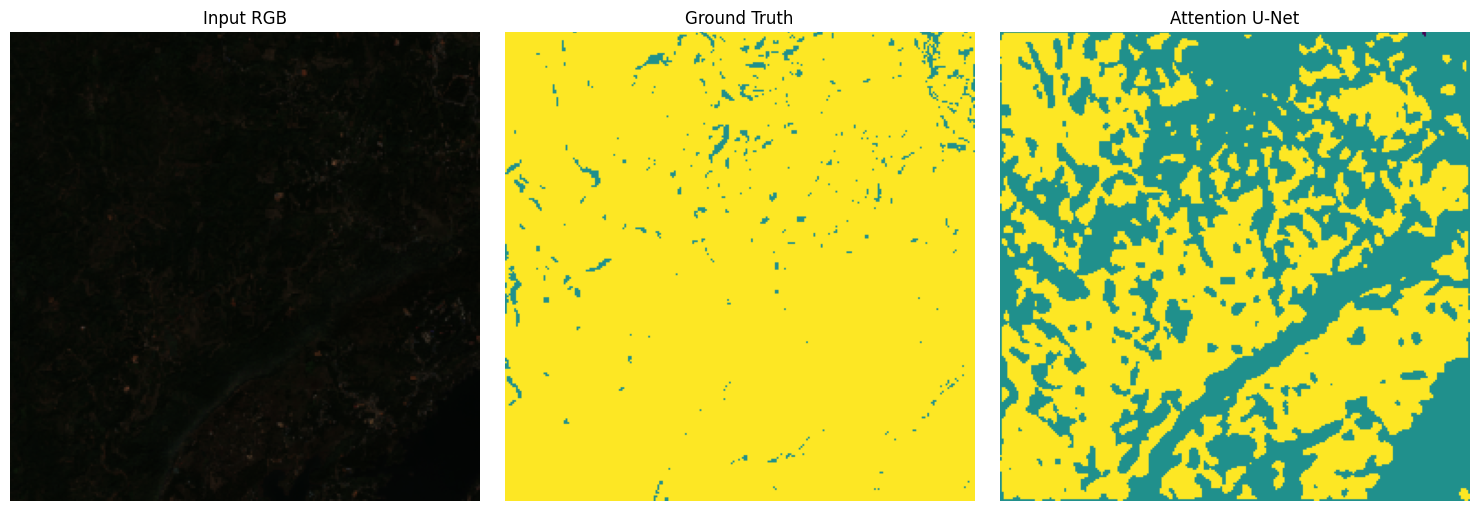

In [ ]:
# ==================================================
# VISUAL COMPARISON
# ==================================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    np.transpose(image[:3], (1, 2, 0))
)
plt.title("Input RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ground_truth, cmap="viridis", vmin=0, vmax=2)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prediction, cmap="viridis", vmin=0, vmax=2)
plt.title("Attention U-Net")
plt.axis("off")

plt.tight_layout()
plt.show()